# Paper key results (view only)

IEEE Latin America Transactions manuscript **ID 11172**.

This notebook **does not train models**. It loads locked numbers from
`../experiments/paper_key_results.json` (`invented=false`) so GitHub viewers
can inspect the manuscript tables without running PyTorch Geometric.

To recompute from code, use `python -m src.train.physagg` (see README).

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
RESULTS = ROOT / "experiments" / "paper_key_results.json"
R = json.loads(RESULTS.read_text(encoding="utf-8"))
assert R.get("invented") is False, "Refusing invented numbers"
print("Source:", R["source"])
print("Manuscript:", R["manuscript_id"])

Source: Tables and prose in IEEE LATAM R1 manuscript (fail-closed; not regenerated here)
Manuscript: 11172


## Fragmentation (isolation vs co-observation filter)

,isolate_pct
min co-obs = 1,8.2
min co-obs = 2,85.1
min co-obs = 3,95.2


Default isolate fraction: 85.1%


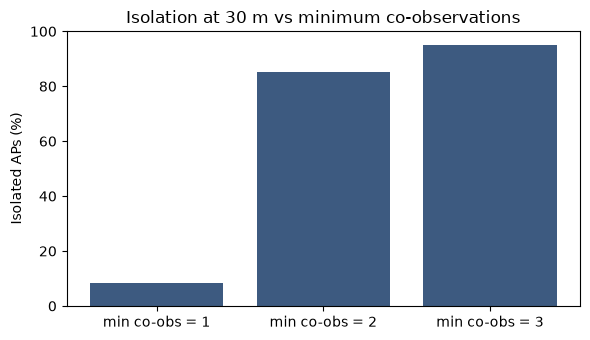

In [2]:
frag = R["fragmentation"]
sens = pd.Series(frag["sensitivity_30m_min_coobs"], name="isolate_pct")
sens.index = sens.index.map(lambda k: f"min co-obs = {k}")
display(sens.to_frame())
print(f"Default isolate fraction: {frag['isolate_fraction_default_pct']}%")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(sens.index, sens.values, color="#3d5a80")
ax.set_ylabel("Isolated APs (%)")
ax.set_title("Isolation at 30 m vs minimum co-observations")
ax.set_ylim(0, 100)
fig.tight_layout()
plt.show()

## RF ablation (remove OPEN/WEP label proxies)

In [3]:
rf = R["rf_label_proxy_ablation"]
rf_df = pd.DataFrame([
    {"level": "Observation", "full": rf["observation_pr_auc_full"], "without_proxies": rf["observation_pr_auc_without_proxies"]},
    {"level": "Node SAFE", "full": rf["node_safe_pr_auc_full"], "without_proxies": rf["node_safe_pr_auc_without_proxies"]},
])
rf_df["delta"] = rf_df["without_proxies"] - rf_df["full"]
display(rf_df.round(3))

,level,full,without_proxies,delta
0,Observation,0.749,0.420,-0.329
1,Node SAFE,0.670,0.297,-0.373


## PhysAgg-R ablation (temporal non-isolate)

,run,seed_42,mean,std
0,A0 GraphSAGE,0.883,0.880,0.002
1,A1 nodal physics,0.798,0.823,0.034
2,A2 PhysAgg operator,0.881,0.880,0.003
3,A2e PhysAgg + L_edge,0.887,0.886,0.005
4,A3 PhysAgg + nodal,0.887,0.880,0.005
5,RF fair (same mask),0.999,NaN,NaN


McNemar A2e vs A0: p≈0.8 (not significant in-domain)


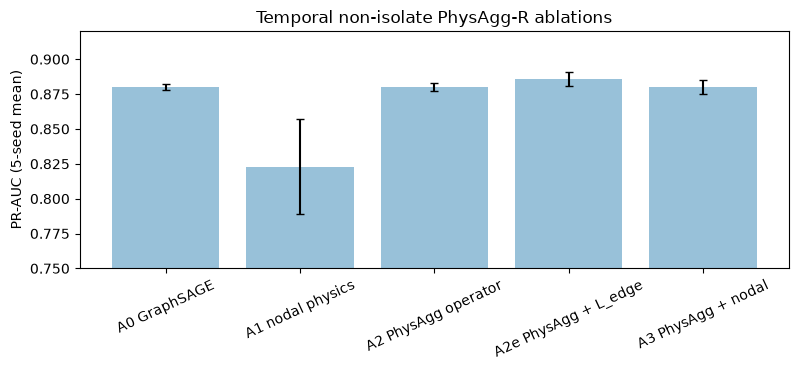

In [4]:
abl = R["physagg_ablation_temporal_non_isolate"]
abl_df = pd.DataFrame(abl["rows"])
display(abl_df)
print(
    f"McNemar A2e vs A0: p≈{abl['mcnemar_A2e_vs_A0_p']} "
    f"({abl['mcnemar_note']})"
)

plot_df = abl_df.dropna(subset=["mean"]).copy()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(plot_df["run"], plot_df["mean"], yerr=plot_df["std"], capsize=3, color="#98c1d9")
ax.set_ylabel("PR-AUC (5-seed mean)")
ax.set_title("Temporal non-isolate PhysAgg-R ablations")
ax.set_ylim(0.75, 0.92)
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

## Municipality hold-out (Suchiapa) and end-to-end summary

,run,pr_auc
0,A0 GraphSAGE,0.628
4,A3 PhysAgg + nodal,0.625
1,A1 nodal physics,0.597
3,A2e PhysAgg + L_edge,0.581
2,A2 PhysAgg operator,0.576


McNemar A0 vs A2e: p≈0.019


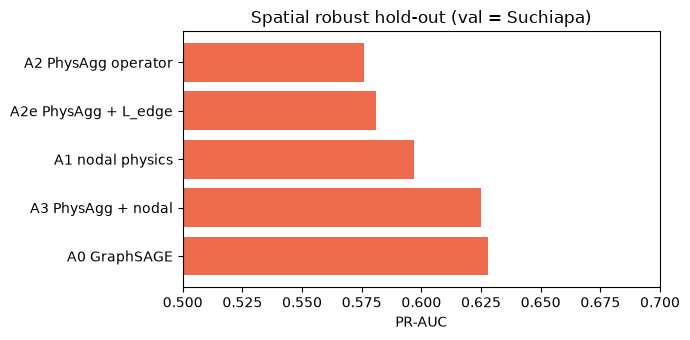

Detection summary


,split,model,pr_auc,note
0,Temporal full,SAGE / RF,0.50 / 0.60,isolates dominate
1,Temporal connected,A2e (5-seed),0.886±0.005,best GNN
2,Temporal isolate,SAGE / RF,0.37 / 0.42,tabular lead
3,Spatial robust,A0,0.628,A2e 0.581


In [5]:
sp = R["spatial_holdout_suchiapa"]
sp_df = pd.DataFrame(sp["rows"]).sort_values("pr_auc", ascending=False)
display(sp_df)
print(f"McNemar A0 vs A2e: p≈{sp['mcnemar_A0_vs_A2e_p']}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(sp_df["run"], sp_df["pr_auc"], color="#ee6c4d")
ax.set_xlabel("PR-AUC")
ax.set_title("Spatial robust hold-out (val = Suchiapa)")
ax.set_xlim(0.5, 0.7)
fig.tight_layout()
plt.show()

print("Detection summary")
display(pd.DataFrame(R["detection_summary"]))